# Mean interpolation heatmaps and task 1 training/path curves

Each column shows one algorithm. Top: the mean task 1 return over seeds at each evaluated policy on the 200 × 200 grid, normalized by the environment maximum. The red dashed path connects θ₁ → θ₂ → θ₃, as in `linear_grid.ipynb`. 

Bottom: the mean task 1 training curve and mean path return, both with shaded 95% bootstrap confidence intervals over seeds. Training data comes from the existing `mean_ci` compute-only CSVs; path returns are estimated by bilinear interpolation of the evaluated grid for each seed, then bootstrapped. The exact straight paths lie between grid rows/columns because the grid omits coordinates 0 and 1. The bottom row uses the typography, colors, and line sizing of `task1_training_linear_path.ipynb`.


In [1]:
from pathlib import Path
import sys

STYLE_ROOT = Path.cwd()
if not (STYLE_ROOT / "scripts" / "plot_style.py").is_file():
    STYLE_ROOT = STYLE_ROOT.parent
if not (STYLE_ROOT / "scripts" / "plot_style.py").is_file():
    raise FileNotFoundError("Start the notebook in the repository root or scripts/.")
sys.path.insert(0, str(STYLE_ROOT))
sys.path.insert(0, str(STYLE_ROOT / "scripts"))
# Reload edits from disk when rerunning this cell in an existing kernel.
import importlib
from scripts import plot_style
importlib.reload(plot_style)
from scripts.plot_style import (
    apply_style, figure_size, export_figure, bottom_legend, FONT_SIZE, STROKES,
)
apply_style()

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sys
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd()
if not (ROOT / "scripts" / "plot_iqm.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "scripts" / "plot_iqm.py").is_file():
    raise FileNotFoundError("Start the kernel in the repository root or scripts/.")
sys.path.insert(0, str(ROOT))
from scripts.common import bootstrap_mean

# Edit a panel's CSV and grid together when selecting a different run.
COMMON = {"plot_index": 0, "line_index": 0, "seeds": range(50),
          "num_tasks": 3, "path_points": 101,
          "path_segments": [("theta1", "theta2"), ("theta2", "theta3")]}
PLOTS = [
    {**COMMON, "title": "DQN", "training_csv": ROOT / "output/plots/joint_incremental/ji-dqn_data.csv",
     "grid_template": ROOT / "output/interpolations/joint_incremental/ji-dqn/data_{seed}.csv",
     "timesteps_per_task": 200_000, "max_return": 500.0},
    {**COMMON, "title": "SAC-D", "training_csv": ROOT / "output/plots/joint_incremental/ji-sacd_data.csv",
     "grid_template": ROOT / "output/interpolations/joint_incremental/ji-sacd-l_00001/data_{seed}.csv",
     "timesteps_per_task": 150_000, "max_return": 500.0},
    {**COMMON, "title": "DDPG", "training_csv": ROOT / "output/plots/joint_incremental/ji-ddpg_data.csv",
     "grid_template": ROOT / "output/interpolations/joint_incremental/ji-ddpg/data_{seed}.csv",
     "timesteps_per_task": 150_000, "max_return": 1000.0},
    {**COMMON, "title": "SAC", "training_csv": ROOT / "output/plots/joint_incremental/ji-sac_data.csv",
     "grid_template": ROOT / "output/interpolations/joint_incremental/ji-sac/data_{seed}.csv",
     "timesteps_per_task": 150_000, "max_return": 1000.0},
]
SOLUTIONS = {"theta1": (0.0, 1.0), "theta2": (1.0, 1.0), "theta3": (1.0, 0.0)}
SOLUTION_CHECKPOINT = {"theta1": 1, "theta2": 2, "theta3": 3}
TRAIN_COLOR = "#E69F00"
PATH_COLOR = "#D62728"
X_LABEL = r"Cumulative training timesteps ($\times 10^5$)"
Y_LABEL = "Task 1 mean normalized return"
SAVE = True
OUT = ROOT / "output/plots/notebook"
OUTPUT_STEM = "linear_grid_training_path_combined_mean_ci"



In [2]:
def load_training(cfg):
    path = Path(cfg["training_csv"])
    frame = pd.read_csv(path)
    required = {"plot_index", "line_index", "aggregation", "timestep", "center", "lower", "upper"}
    if not required.issubset(frame):
        raise ValueError(f"{path}: missing {sorted(required - set(frame))}")
    selected = frame.loc[(frame.plot_index == cfg["plot_index"]) &
                         (frame.line_index == cfg["line_index"])].copy()
    if selected.empty or set(selected.aggregation.dropna()) != {"mean_ci"}:
        raise ValueError(f"{path}: expected one matching mean_ci training line.")
    selected = selected.sort_values("timestep")
    for column in ("timestep", "center", "lower", "upper"):
        selected[column] = pd.to_numeric(selected[column], errors="raise")
    selected = selected.loc[np.isfinite(selected[["timestep", "center", "lower", "upper"]]).all(axis=1)]
    if selected.empty or (selected.lower > selected.upper).any():
        raise ValueError(f"{path}: no finite training data or invalid bounds.")
    return selected


def read_grid(path):
    frame = pd.read_csv(path, header=None, names=["alpha", "beta", "reward"])
    if frame.empty or not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError(f"Empty or non-finite grid: {path}")
    grid = frame.pivot(index="beta", columns="alpha", values="reward").sort_index().sort_index(axis=1)
    if grid.isna().any().any():
        raise ValueError(f"Incomplete grid: {path}")
    return grid.index.to_numpy(float), grid.columns.to_numpy(float), grid.to_numpy(float)


def load_grid_stack(cfg):
    matrices = []
    beta_axis = alpha_axis = None
    for seed in cfg["seeds"]:
        path = Path(str(cfg["grid_template"]).format(seed=seed))
        if not path.is_file():
            raise FileNotFoundError(f"Missing {path}")
        beta, alpha, rewards = read_grid(path)
        if beta_axis is None:
            beta_axis, alpha_axis = beta, alpha
        elif not (np.array_equal(beta, beta_axis) and np.array_equal(alpha, alpha_axis)):
            raise ValueError(f"Grid axes differ across seeds: {path}")
        matrices.append(rewards)
    if len(matrices) < 2:
        raise ValueError("At least two grid seeds are required for a confidence interval.")
    return beta_axis, alpha_axis, np.asarray(matrices)


def grid_performance(beta_axis, alpha_axis, rewards, alpha, beta):
    """Bilinear reward estimate at exact (alpha, beta) parameter coordinates."""
    if not (alpha_axis[0] <= alpha <= alpha_axis[-1] and beta_axis[0] <= beta <= beta_axis[-1]):
        raise ValueError("Path lies outside the evaluated grid.")
    below = int(np.clip(np.searchsorted(beta_axis, beta, side="right") - 1, 0, len(beta_axis) - 2))
    weight = (beta - beta_axis[below]) / (beta_axis[below + 1] - beta_axis[below])
    return ((1 - weight) * np.interp(alpha, alpha_axis, rewards[below]) +
            weight * np.interp(alpha, alpha_axis, rewards[below + 1]))


def path_stats(cfg, beta_axis, alpha_axis, grids):
    progress = np.linspace(0, 1, cfg["path_points"])
    segments = cfg["path_segments"]
    coordinates = []
    for first, second in segments:
        a, b = np.asarray(SOLUTIONS[first]), np.asarray(SOLUTIONS[second])
        coordinates.extend(a[None, :] + progress[:, None] * (b - a)[None, :])
    values = np.array([[grid_performance(beta_axis, alpha_axis, grid, a, b)
                        for a, b in coordinates] for grid in grids]).T
    center, lower, upper = bootstrap_mean(values, n_bootstrap=10_000, confidence=.95)
    n = len(progress)
    return [(first, second, progress, center[i*n:(i+1)*n],
             lower[i*n:(i+1)*n], upper[i*n:(i+1)*n])
            for i, (first, second) in enumerate(segments)]


def validate_endpoints(cfg, training, paths):
    for first, second, _, center, _, _ in paths:
        for name, reward in ((first, center[0]), (second, center[-1])):
            timestep = SOLUTION_CHECKPOINT[name] * cfg["timesteps_per_task"]
            closest = training.iloc[(training.timestep - timestep).abs().argmin()]
            if abs(closest.timestep - timestep) > .01 * cfg["timesteps_per_task"]:
                raise ValueError(f"{cfg['title']}: no training measurement near {name}.")
            if abs(reward - closest.center) / cfg["max_return"] > .1:
                raise ValueError(f"{cfg['title']} {name}: grid and training returns disagree; check paths.")

panel_data = []
for cfg in PLOTS:
    training = load_training(cfg)
    beta_axis, alpha_axis, grids = load_grid_stack(cfg)
    mean_grid = grids.mean(axis=0) / cfg["max_return"]
    paths = path_stats(cfg, beta_axis, alpha_axis, grids)
    validate_endpoints(cfg, training, paths)
    panel_data.append((cfg, training, beta_axis, alpha_axis, mean_grid, paths))
    print(f"{cfg['title']}: {len(grids)} seeds, {len(training)} training points")


DQN: 50 seeds, 2748 training points
SAC-D: 50 seeds, 2598 training points
DDPG: 50 seeds, 2598 training points
SAC: 50 seeds, 2598 training points


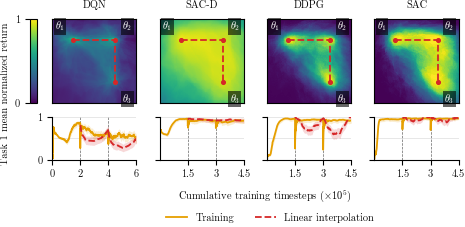

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
webf NOT subset; don't know how to subset; dropped


Saved /home/seb/Code/uni/stability-gap-drl/output/plots/notebook/linear_grid_training_path_combined_mean_ci.pdf
Saved /home/seb/Code/uni/stability-gap-drl/output/plots/notebook/linear_grid_training_path_combined_mean_ci.png
Saved /home/seb/Code/uni/stability-gap-drl/output/plots/notebook/linear_grid_training_path_combined_mean_ci.svg


In [3]:
def format_timestep(value, _position):
    return f"{value / 100_000:g}"

fig = plt.figure(figsize=figure_size("combined"))
gs = fig.add_gridspec(2, 5, width_ratios=[.075, 1, 1, 1, 1],
                      height_ratios=[2, 1], left=.08, right=.99,
                      bottom=.30, top=.88, wspace=.08, hspace=.22)
heat_axes = [fig.add_subplot(gs[0, i + 1]) for i in range(4)]
curve_axes = [fig.add_subplot(gs[1, i + 1]) for i in range(4)]
mean_cax = fig.add_subplot(gs[0, 0])

for column, (ax_heat, ax_curve, data) in enumerate(zip(heat_axes, curve_axes, panel_data)):
    cfg, training, beta_axis, alpha_axis, mean_grid, paths = data
    extent = (alpha_axis[0], alpha_axis[-1], beta_axis[0], beta_axis[-1])
    mean_image = ax_heat.imshow(mean_grid, origin="lower", extent=extent,
                                vmin=0, vmax=1, cmap="viridis", interpolation="nearest")
    ax_heat.plot([0, 1, 1], [1, 1, 0], color=PATH_COLOR, linestyle="--", linewidth=STROKES["curve"])
    ax_heat.scatter([0, 1, 1], [1, 1, 0], s=8, color=PATH_COLOR, zorder=3)
    for x, y, name, offset in [(0, 1, r"$\theta_1$", (-6, 5)),
                               (1, 1, r"$\theta_2$", (5, 5)),
                               (1, 0, r"$\theta_3$", (5, -7))]:
        ax_heat.annotate(name, (x, y), xytext=offset, textcoords="offset points",
                         color="white", ha="right" if offset[0] < 0 else "left",
                         va="bottom" if offset[1] > 0 else "top",
                         bbox={"facecolor": "black", "alpha": .6, "edgecolor": "none", "pad": 1})
    ax_heat.set_title(cfg["title"], pad=8)
    ax_heat.set_xticks([])
    ax_heat.set_yticks([])

    scale = cfg["max_return"]
    times = training.timestep.to_numpy(float)
    ax_curve.plot(times, training.center.to_numpy() / scale,
                  color=TRAIN_COLOR, label="Training")
    ax_curve.fill_between(times, training.lower.to_numpy() / scale,
                          training.upper.to_numpy() / scale,
                          color=TRAIN_COLOR, alpha=.18, linewidth=STROKES["band_edge"])
    for index, (first, second, progress, center, lower, upper) in enumerate(paths):
        path_times = cfg["timesteps_per_task"] * (
            SOLUTION_CHECKPOINT[first] + progress *
            (SOLUTION_CHECKPOINT[second] - SOLUTION_CHECKPOINT[first]))
        ax_curve.plot(path_times, center / scale, color=PATH_COLOR, linestyle="--",
                      label="Linear interpolation" if index == 0 else None)
        ax_curve.fill_between(path_times, lower / scale, upper / scale,
                              color=PATH_COLOR, alpha=.18, linewidth=STROKES["band_edge"])
    total = cfg["timesteps_per_task"] * cfg["num_tasks"]
    for boundary in range(1, cfg["num_tasks"]):
        ax_curve.axvline(boundary * cfg["timesteps_per_task"], color="0.4",
                         linewidth=STROKES["task_boundary"], linestyle="--", zorder=0)
    ax_curve.set(xlim=(0, total), ylim=(0, 1))
    ax_curve.set_box_aspect(.5)  # plot_iqm.py uses 10 x 5 for standard curves
    ax_curve.set_yticks([0, 1], labels=["0", "1"])
    tick_tasks = np.arange(cfg["num_tasks"] + 1)
    if column > 0:
         tick_tasks = tick_tasks[1:]  # avoid adjacent panels' 0/end labels colliding


    ax_curve.set_xticks(tick_tasks * cfg["timesteps_per_task"])
    ax_curve.xaxis.set_major_formatter(FuncFormatter(format_timestep))
    ax_curve.grid(axis="y", color="0.8", alpha=.65)
    ax_curve.axhline(.5, color="0.8", alpha=.65, linewidth=STROKES["grid"], zorder=0)
    ax_curve.spines[["top", "right"]].set_visible(False)
    if column:
        ax_curve.tick_params(axis="y", labelleft=False)


colorbar = fig.colorbar(mean_image, cax=mean_cax, ticks=[0, 1])
colorbar.ax.set_yticklabels(["0", "1"])
colorbar.ax.yaxis.set_ticks_position("left")
colorbar.ax.yaxis.set_label_position("left")
fig.supylabel(Y_LABEL, y=.57, x=.018)
fig.supxlabel(X_LABEL, y=.25 / fig.get_figheight() + .01, x=.57)
handles, labels = curve_axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="lower center", ncol=2,
           bbox_to_anchor=(.58, 0))
plt.show()

if SAVE:
    OUT.mkdir(parents=True, exist_ok=True)
    for suffix in ("pdf", "png", "svg"):
        output = OUT / f"{OUTPUT_STEM}.{suffix}"
        export_figure(fig, output, dpi=300)
        print(f"Saved {output}")
